# Обучение на нескольких днях
## LFPG 09L, 15–18 января 2025

**185 заходов, 161 борт, 3 259 пар наблюдений, прогноз на 30 ± 3 секунды**

Сравниваем 11 семейств моделей и два способа обучения: поправку к продолжению текущей вертикальной скорости и прямой прогноз будущей высоты. Все модели используют одни и те же девять признаков.

Два вопроса: переносится ли обучение на следующий день и помогает ли оно для ранее не встречавшихся бортов? Дополнительно смотрим, что дает второй обучающий день, какие признаки влияют на прогноз и как меняется ответ при изменении Vz.

Высота здесь является барометрическим прокси над уровнем аэропорта. Это исследование высотного прогноза до прокси 300 ft; меток ухода на второй круг в этих данных нет.

day,approaches,aircraft,examples
2025-01-15,37,35,633
2025-01-16,36,35,630
2025-01-17,66,66,1124
2025-01-18,46,45,872


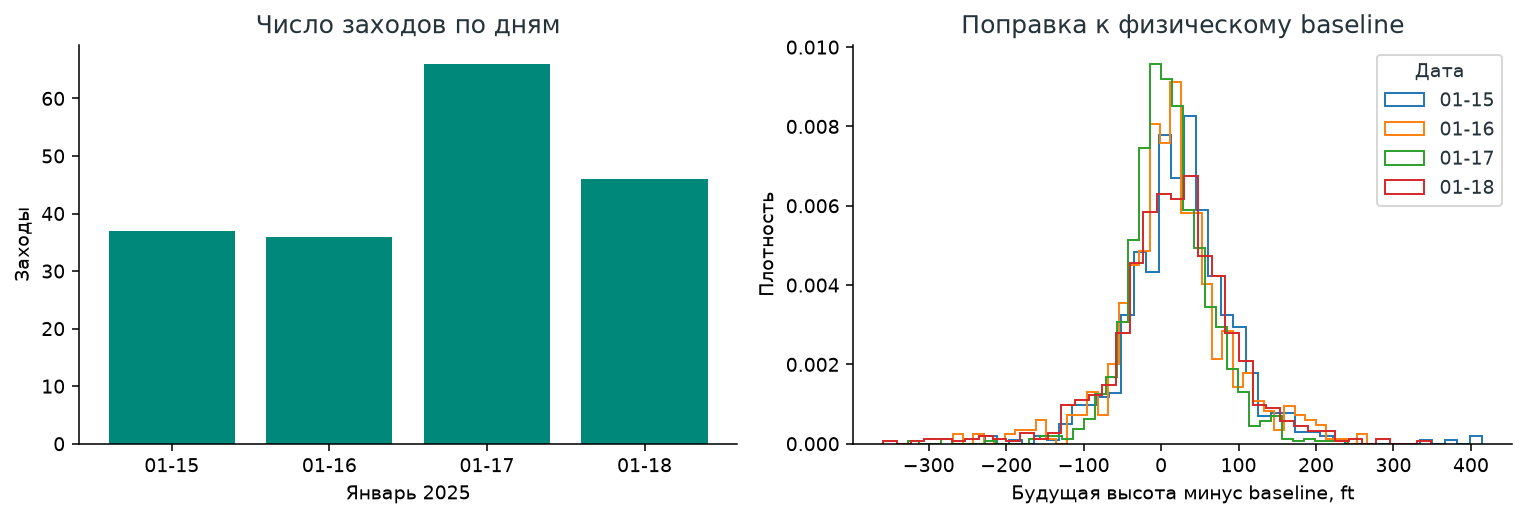

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
BASE = Path.cwd()
if BASE.name == 'notebooks':
    BASE = BASE.parent
PROJECT = BASE.parents[1]
sys.path.insert(0, str(PROJECT / 'scripts'))
from lfpg_multiday import load_data, split_data, run, BASELINES
from lfpg_multiday import predict
from lfpg_training import summarize
data, FEATURES = load_data(BASE)
RED, GREEN, INK, GREY = '#D65A4A', '#00897B', '#25343B', '#829198'
plt.rcParams.update({'figure.dpi': 140, 'font.size': 10, 'axes.titlesize': 13,
    'axes.spines.top': False, 'axes.spines.right': False, 'figure.facecolor': 'white',
    'text.color': INK, 'svg.hashsalt': 'lfpg-multiday-06'})
def table(frame):
    formats = {col: '{:.0f}' if pd.api.types.is_integer_dtype(frame[col]) else '{:.2f}'
               for col in frame.select_dtypes(include='number').columns}
    display(frame.style.format(formats).hide(axis='index').set_properties(**{'padding': '8px'})
        .set_table_styles([{'selector':'th','props':[('background-color','#E8F3F1')]}]))
def figure(fig, name):
    fig.tight_layout()
    fig.savefig(BASE / 'figures' / (name + '.png'), dpi=180, bbox_inches='tight')
    svg = BASE / 'figures' / (name + '.svg')
    fig.savefig(svg, bbox_inches='tight', metadata={'Date':None})
    svg.write_text(chr(10).join(line.rstrip() for line in svg.read_text(encoding='utf-8').splitlines()) + chr(10), encoding='utf-8')
    plt.show()
daily = data.groupby('day').agg(approaches=('event_id','nunique'),
    aircraft=('icao24','nunique'), examples=('event_id','size')).reset_index()
table(daily)
fig, axes = plt.subplots(1,2,figsize=(11,3.8))
axes[0].bar(daily.day.str[5:], daily.approaches, color=GREEN)
axes[0].set(title='Число заходов по дням',ylabel='Заходы',xlabel='Январь 2025')
for day, group in data.groupby('day'):
    axes[1].hist(group.residual_ft,bins=40,histtype='step',density=True,label=day[5:])
axes[1].set(title='Поправка к физическому baseline',xlabel='Будущая высота минус baseline, ft',ylabel='Плотность')
axes[1].legend(title='Дата')
figure(fig,'06_days_and_baseline')

## Две проверки переноса

**Новый день:** train = 15–16 января, validation = 17 января, test = 18 января. Борт может встретиться в разные дни; идентификаторы бортов и даты не входят в признаки. Это проверка переноса во времени, а не проверка нового борта.

**Новые борта:** все четыре дня объединяются и делятся по ICAO24 на train, validation и test. Один борт целиком остается в одной части. В этой проверке дни перемешаны; она не оценивает прогноз будущего дня. Часть данных 15 января уже исследовалась раньше.

Каждый заход имеет равный суммарный вес в обучении и в основной метрике MAE. Масштабирование учится только на train. Параметры и способ прогноза выбираются по validation; после этого все выбранные варианты один раз оцениваются на test. Выбор не пересматривается по test.

In [2]:
splits = []
for scheme in ['next_day','new_aircraft']:
    assigned = split_data(data,scheme)
    summary = assigned.groupby('split').agg(approaches=('event_id','nunique'),
        aircraft=('icao24','nunique'),examples=('event_id','size')).reset_index()
    summary['scheme'] = scheme
    splits.append(summary)
    if scheme == 'next_day':
        seen = set(assigned.loc[assigned.split.eq('train'),'icao24'])
        test_aircraft = set(assigned.loc[assigned.split.eq('test'),'icao24'])
        print('В test нового дня бортов, встречавшихся на train:', len(seen & test_aircraft), 'из',len(test_aircraft))
table(pd.concat(splits,ignore_index=True))
table(pd.DataFrame({'feature':FEATURES}))

split,approaches,aircraft,examples,scheme
test,46,45,872,next_day
train,73,68,1263,next_day
validation,66,66,1124,next_day
test,40,33,715,new_aircraft
train,108,96,1906,new_aircraft
validation,37,32,638,new_aircraft


feature
height_ft
vertical_rate_fps
past_height_rate_fps
speed_knots
distance_m
lateral_m
heading_error_deg
past_gap_s
horizon_s


В test нового дня бортов, встречавшихся на train: 4 из 45


## Обучение 184 вариантов

Линейные модели: Ridge, ElasticNet, Huber. Нелинейные: SVR RBF, полиномиальная Ridge и MLP. Ансамбли: Random Forest, Extra Trees, Gradient Boosting, Hist Gradient Boosting и CatBoost.

**Поправка:** модель учит `future_height - baseline`, а прогноз равен `baseline + model(features)`.

**Прямая высота:** модель учит `future_height`. В обоих случаях доступны только признаки момента прогноза и предшествующая история. Будущая точка используется исключительно как целевое наблюдение.

MLP использует масштабирование признаков и целевой переменной. Все модели получают веса заходов. Варианты, для которых оптимизатор не сошелся, не участвуют в выборе. [MLPRegressor](https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPRegressor.html), [CatBoostRegressor](https://catboost.ai/docs/en/concepts/python-reference_catboostregressor).

In [3]:
# Выполняем обучение и сохраняем модели для повторного прогноза
result = run(BASE, progress=lambda message: print(message,file=sys.__stdout__,flush=True))
search = result['search']
table(search.groupby(['scheme','family']).agg(fits=('candidate','size'),
    converged=('converged','sum'),seconds=('seconds','sum')).reset_index())
print('Всего вариантов:',len(search),'несошедшихся:',int((~search.converged).sum()))
for scheme, name in result['bundle']['winner_by_validation'].items():
    print('Выбранная на validation модель:',scheme,name)
table(result['selected'][['scheme','family','mode','validation_mae_ft','parameters']])

scheme,family,fits,converged,seconds
new_aircraft,CatBoost,8,8,4.09
new_aircraft,ElasticNet,12,12,0.21
new_aircraft,Extra Trees,8,8,1.59
new_aircraft,Gradient Boosting,8,8,3.89
new_aircraft,Hist Gradient Boosting,8,8,2.49
new_aircraft,Huber,6,6,0.12
new_aircraft,MLP,4,3,13.25
new_aircraft,Polynomial Ridge,8,8,0.17
new_aircraft,Random Forest,8,8,4.71
new_aircraft,Ridge,10,10,0.15


scheme,family,mode,validation_mae_ft,parameters
next_day,Ridge,residual,16.01,"{""solver"": ""svd"", ""alpha"": 1}"
next_day,Ridge,direct,16.73,"{""solver"": ""svd"", ""alpha"": 0.1}"
next_day,ElasticNet,residual,17.36,"{""max_iter"": 50000, ""tol"": 1e-05, ""alpha"": 0.01, ""l1_ratio"": 0.5}"
next_day,ElasticNet,direct,17.64,"{""max_iter"": 50000, ""tol"": 1e-05, ""alpha"": 0.01, ""l1_ratio"": 0.5}"
next_day,Huber,residual,16.52,"{""alpha"": 0.1, ""max_iter"": 5000, ""tol"": 1e-05, ""epsilon"": 2.0}"
next_day,Huber,direct,16.74,"{""alpha"": 0.1, ""max_iter"": 5000, ""tol"": 1e-05, ""epsilon"": 1.2}"
next_day,SVR RBF,residual,16.31,"{""kernel"": ""rbf"", ""epsilon"": 5.0, ""cache_size"": 200, ""C"": 1000, ""gamma"": 0.03}"
next_day,SVR RBF,direct,18.61,"{""kernel"": ""rbf"", ""epsilon"": 5.0, ""cache_size"": 200, ""C"": 1000, ""gamma"": 0.03}"
next_day,Random Forest,residual,18.76,"{""n_estimators"": 200, ""n_jobs"": 1, ""max_depth"": 6, ""min_samples_leaf"": 5}"
next_day,Random Forest,direct,27.67,"{""n_estimators"": 200, ""n_jobs"": 1, ""max_depth"": 6, ""min_samples_leaf"": 5}"


Всего вариантов: 184 несошедшихся: 2
Выбранная на validation модель: next_day Polynomial Ridge / residual
Выбранная на validation модель: new_aircraft Polynomial Ridge / direct


## Главная таблица

В каждой строке семейства показан способ обучения с меньшей MAE на validation данной проверки. Состав test-заходов общий для всех моделей внутри проверки. MAE усредняется сначала внутри захода, затем между заходами. P95 относится к отдельным ошибкам точек и не является 95-процентным доверительным интервалом.

Основное сравнение нового дня: 46 заходов и 872 примера 18 января. Сравнение новых бортов: 40 заходов и 715 примеров. Победитель по validation сохраняется независимо от ранжирования на test.

family,mode,validation_mae_ft,macro_mae_ft,macro_rmse_ft,point_p95_abs_ft,new_aircraft_mae_ft,new_aircraft_mode,improvement_percent
Ridge,residual,16.01,17.52,23.74,52.16,16.58,direct,68.69
Polynomial Ridge,residual,15.79,17.99,24.27,52.19,16.28,direct,67.87
Huber,residual,16.52,18.33,25.02,55.65,16.31,direct,67.26
SVR RBF,residual,16.31,19.15,25.89,54.05,16.63,residual,65.79
ElasticNet,residual,17.36,20.11,27.14,58.97,16.57,direct,64.07
MLP,direct,17.69,21.09,27.74,57.46,17.62,direct,62.32
CatBoost,residual,17.88,26.21,33.75,70.26,17.25,residual,53.18
Gradient Boosting,residual,18.22,26.42,35.11,75.70,18.64,direct,52.80
Hist Gradient Boosting,residual,18.14,27.11,36.14,76.30,18.63,direct,51.57
Random Forest,residual,18.76,28.65,38.28,77.43,19.60,residual,48.82


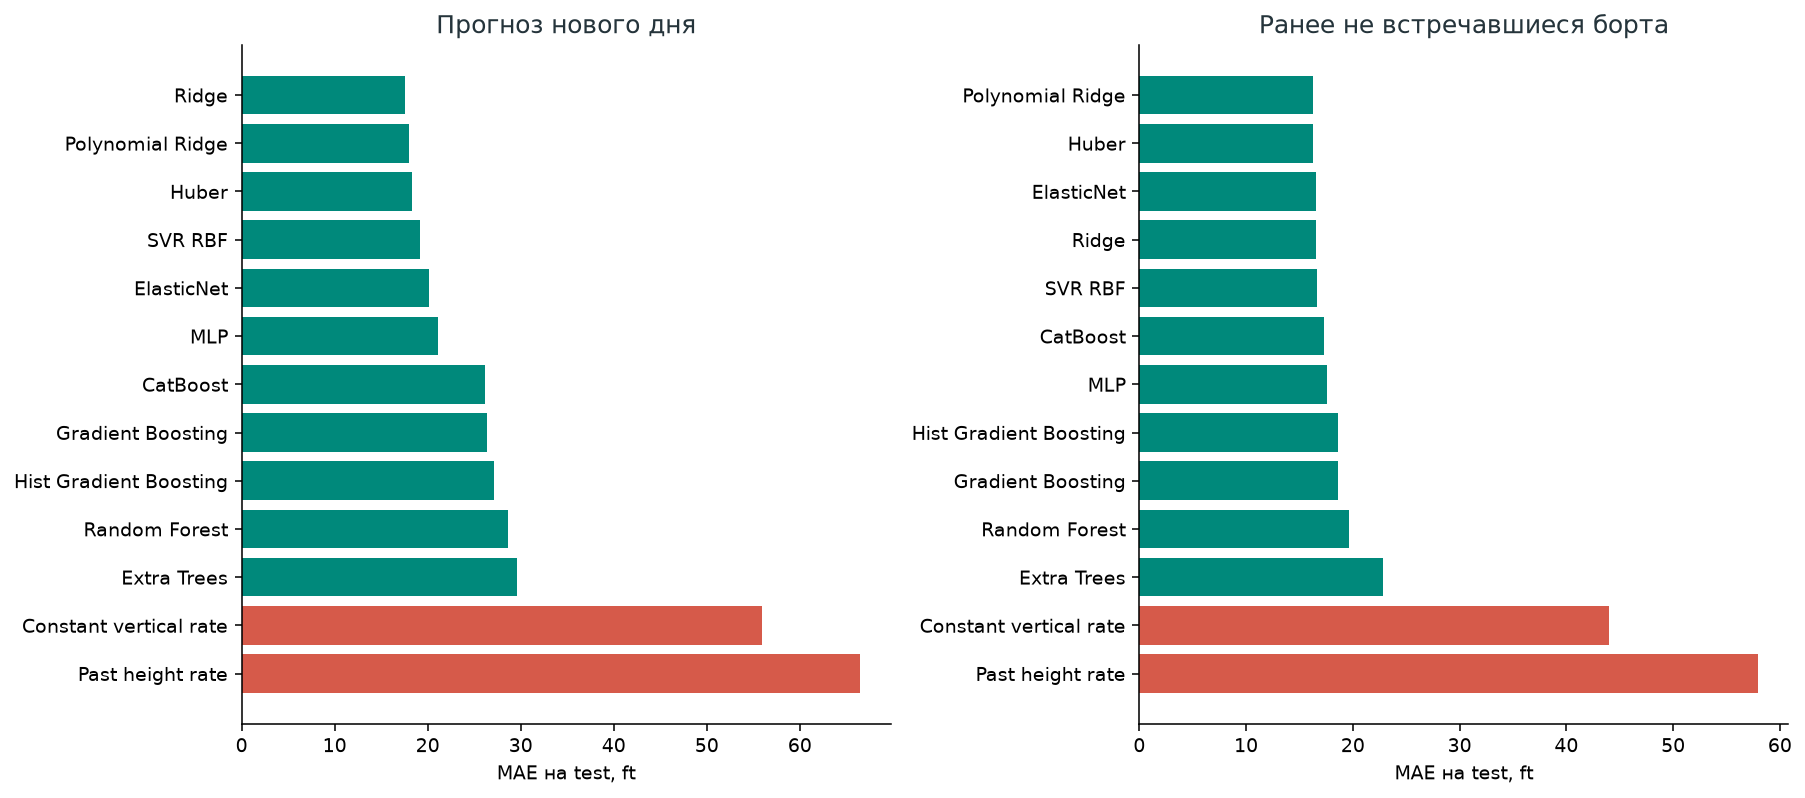

model,delta_macro_mae_ft,interval_2_5_ft,interval_97_5_ft
CatBoost / residual,-29.77,-36.88,-23.57
Constant vertical rate,0.00,0.00,0.00
ElasticNet / residual,-35.86,-42.67,-30.15
Extra Trees / residual,-26.36,-32.17,-21.16
Gradient Boosting / residual,-29.56,-36.54,-23.38
Hist Gradient Boosting / residual,-28.86,-35.49,-22.88
Huber / residual,-37.65,-44.31,-32.05
MLP / direct,-34.88,-41.80,-28.89
Past height rate,10.47,6.78,14.31
Polynomial Ridge / residual,-37.99,-44.55,-32.23


In [4]:
family = result['family_results']
main = family.loc[family.scheme.eq('next_day')].sort_values('macro_mae_ft').copy()
other = family.loc[family.scheme.eq('new_aircraft')].set_index('family')
baseline = float(main.loc[main.family.eq(BASELINES[0]),'macro_mae_ft'].iloc[0])
final = main[['family','mode','validation_mae_ft','macro_mae_ft','macro_rmse_ft','point_p95_abs_ft']].copy()
final['new_aircraft_mae_ft'] = final.family.map(other.macro_mae_ft)
final['new_aircraft_mode'] = final.family.map(other['mode'])
final['improvement_percent'] = 100*(1-final.macro_mae_ft/baseline)
final.to_csv(BASE / 'reports/06_final_table.csv',index=False)
table(final)
fig, axes = plt.subplots(1,2,figsize=(13,5.8))
for ax, scheme, title in zip(axes,['next_day','new_aircraft'],['Прогноз нового дня','Ранее не встречавшиеся борта']):
    part = family.loc[family.scheme.eq(scheme)].sort_values('macro_mae_ft',ascending=False)
    colors = [RED if name in BASELINES else GREEN for name in part.family]
    ax.barh(part.family,part.macro_mae_ft,color=colors)
    ax.set(title=title,xlabel='MAE на test, ft')
figure(fig,'06_model_results')
table(result['intervals'].loc[result['intervals'].scheme.eq('next_day') & result['intervals'].model.isin(main.model),
    ['model','delta_macro_mae_ft','interval_2_5_ft','interval_97_5_ft']])

## Прямой прогноз или поправка?

Теперь смотрим обе постановки для каждого семейства. Параметры внутри постановки выбраны только на validation. Это разбор уже полученных результатов, а не повторный подбор по test.

scheme,family,mode,validation_mae_ft,macro_mae_ft,point_p95_abs_ft
next_day,Ridge,residual,16.01,17.52,52.16
next_day,Ridge,direct,16.73,19.53,50.16
next_day,ElasticNet,residual,17.36,20.11,58.97
next_day,ElasticNet,direct,17.64,20.16,51.61
next_day,Huber,residual,16.52,18.33,55.65
next_day,Huber,direct,16.74,19.14,49.67
next_day,SVR RBF,residual,16.31,19.15,54.05
next_day,SVR RBF,direct,18.61,22.83,68.84
next_day,Random Forest,residual,18.76,28.65,77.43
next_day,Random Forest,direct,27.67,27.60,71.27


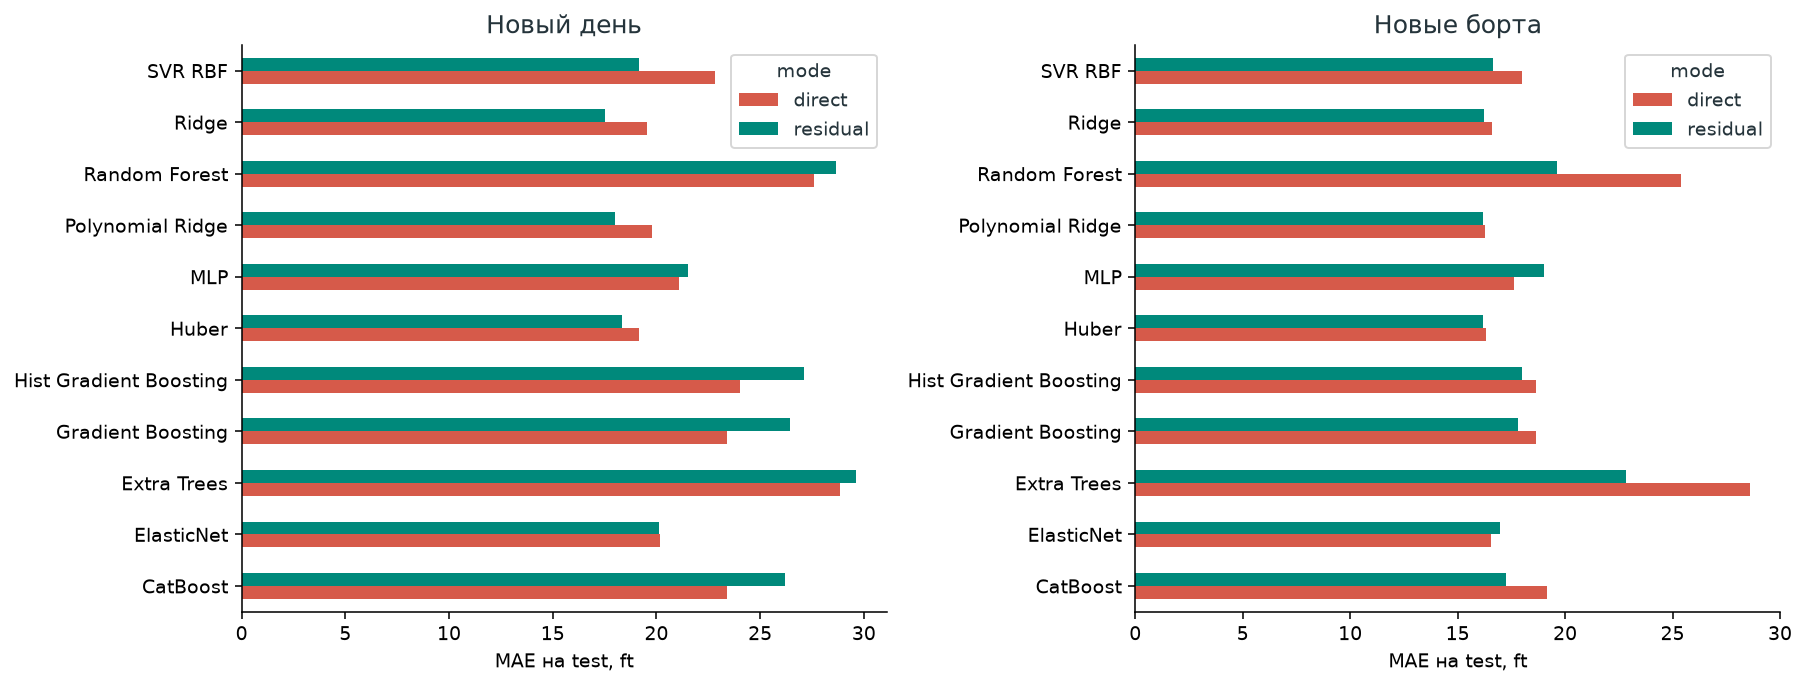

In [5]:
learned = result['metrics'].loc[result['metrics']['mode'].ne('physical')]
table(learned[['scheme','family','mode','validation_mae_ft','macro_mae_ft','point_p95_abs_ft']])
fig, axes = plt.subplots(1,2,figsize=(13,5))
for ax,scheme,title in zip(axes,['next_day','new_aircraft'],['Новый день','Новые борта']):
    comparison = learned.loc[learned.scheme.eq(scheme)].pivot(index='family',columns='mode',values='macro_mae_ft')
    comparison.plot.barh(ax=ax,color=[RED,GREEN])
    ax.set(title=title,xlabel='MAE на test, ft',ylabel='')
figure(fig,'06_direct_and_residual')

## Что дает второй день обучения?

Для модели, выбранной на validation нового дня, сохраняем те же параметры и сравниваем обучение на 15 января, на 16 января и на обоих днях. Test во всех трех случаях один: 18 января. Меньший обучающий набор не получает собственного поиска параметров. Сравнение исследовательское; двух размеров недостаточно для вывода о законе масштабирования.

training_days,training_events,training_examples,macro_mae_ft,point_p95_abs_ft
2025-01-15,37,633,23.65,62.76
2025-01-16,36,630,18.88,54.75
"2025-01-15, 2025-01-16",73,1263,17.99,52.19


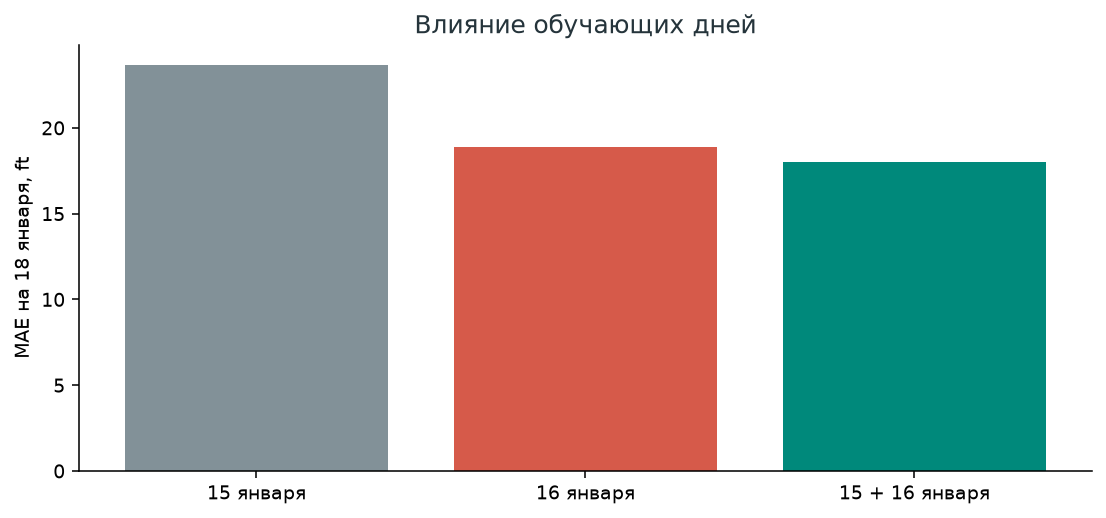

In [6]:
table(result['learning'][['training_days','training_events','training_examples','macro_mae_ft','point_p95_abs_ft']])
fig,ax=plt.subplots(figsize=(8,3.8))
learning=result['learning']
ax.bar(['15 января','16 января','15 + 16 января'],learning.macro_mae_ft,color=[GREY,RED,GREEN])
ax.set(title='Влияние обучающих дней',ylabel='MAE на 18 января, ft')
figure(fig,'06_training_days')

## Признаки и реакция на Vz

Для выбранной модели перемешиваем по одному признаку на validation и измеряем рост ошибки. Связи между высотой, расстоянием и скоростями при таком перемешивании нарушаются: это диагностика зависимости модели, а не причинный эффект. Для поправки пересчитываем и физическую часть прогноза, когда меняются высота, Vz или горизонт.

Отдельно изменяем только текущую Vz на ±1 ft/s. Коэффициент ответа 1 означает реакцию продолжения текущей Vz; 0 означает, что полный прогноз почти не изменился. Остальные признаки фиксированы. Такой искусственный пример не является реальным изменением траектории и не проверяет обнаружение ухода.

feature,validation_mae_increase_ft,std_ft
heading_error_deg,-0.01,0.08
past_gap_s,0.05,0.07
vertical_rate_fps,0.24,0.11
lateral_m,1.52,0.07
past_height_rate_fps,1.83,0.12
horizon_s,14.32,0.46
speed_knots,27.43,0.68
distance_m,140.80,2.82
height_ft,443.65,8.74


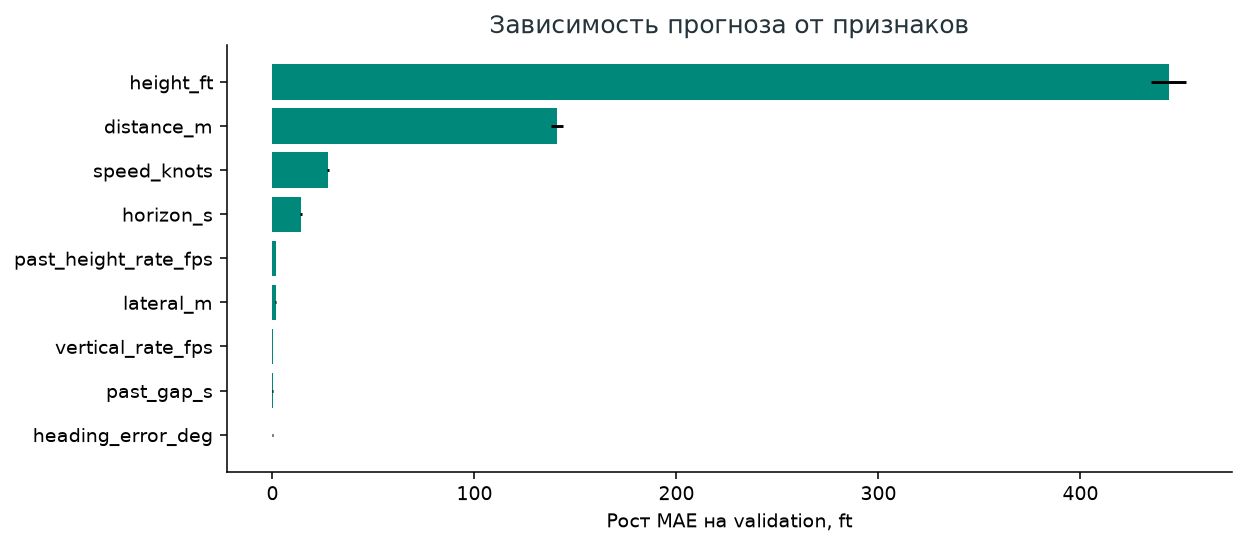

model,median_vz_response_ratio,p10,p90
Constant vertical rate,1.00,1.00,1.00
Past height rate,0.00,0.00,0.00
Ridge / residual,0.03,-0.05,0.09
Ridge / direct,0.02,0.02,0.02
ElasticNet / residual,0.04,-0.04,0.11
ElasticNet / direct,0.02,0.02,0.03
Huber / residual,0.04,-0.04,0.11
Huber / direct,0.04,0.04,0.04
SVR RBF / residual,0.02,-0.07,0.14
SVR RBF / direct,0.03,-0.10,0.16


In [7]:
importance=result['importance'].sort_values('validation_mae_increase_ft')
table(importance)
fig,ax=plt.subplots(figsize=(9,4))
ax.barh(importance.feature,importance.validation_mae_increase_ft,xerr=importance.std_ft,color=GREEN)
ax.set(title='Зависимость прогноза от признаков',xlabel='Рост MAE на validation, ft')
figure(fig,'06_feature_influence')
table(result['vz_response'])

## Посмотрим сами прогнозы

Три test-захода выбираются по ошибке модели, выбранной на validation: лучший, средний и худший. Это иллюстрации разброса, а не три дополнительных независимых проверки.

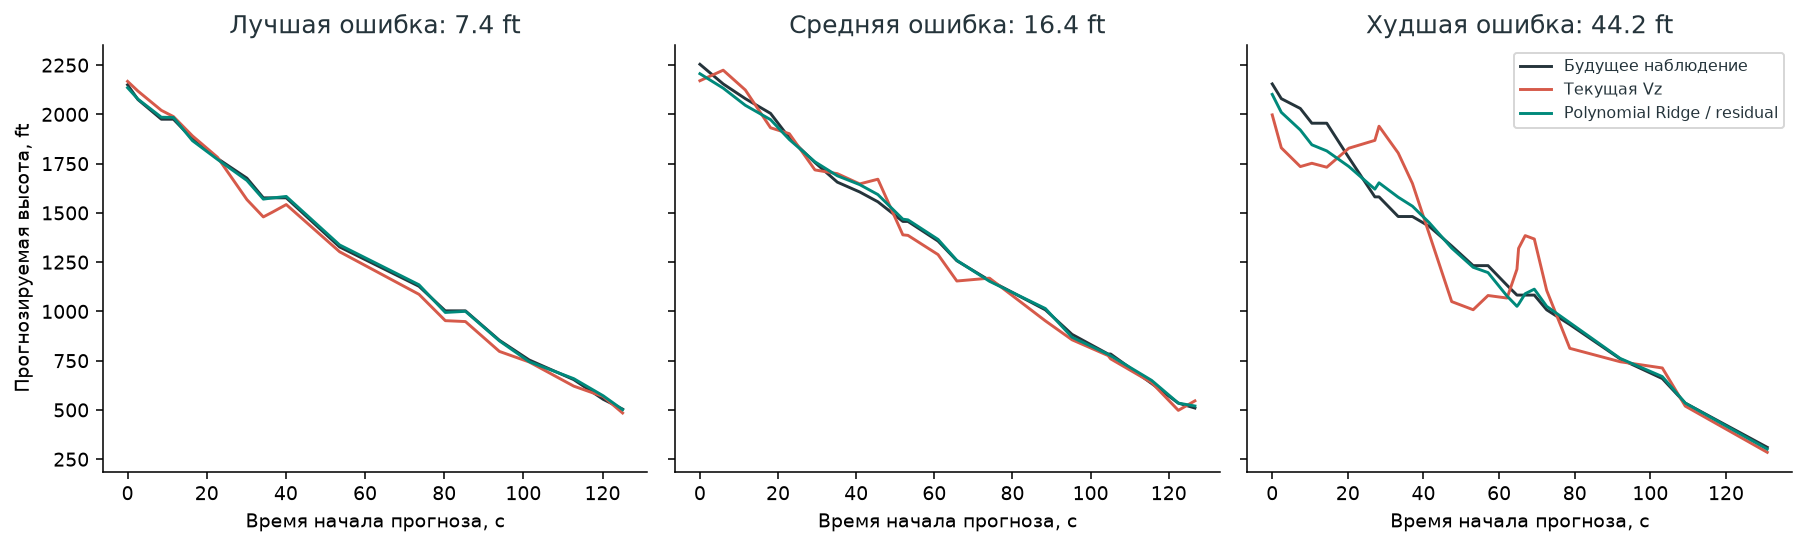

event_id,icao24,mae_ft,bias_ft,examples
7e4a09ad093a6867,4b19f2,7.39,-0.16,19
fc84f81208b85bfb,4baa53,16.38,-0.00,21
f028fd880e2712bb,392af9,44.21,-15.64,25


In [8]:
winner=result['bundle']['winner_by_validation']['next_day']
errors=result['event_errors'].loc[result['event_errors'].scheme.eq('next_day') & result['event_errors'].model.eq(winner)].sort_values('mae_ft')
chosen=errors.iloc[[0,len(errors)//2,-1]]
temporal=split_data(data,'next_day')
test=temporal.loc[temporal.split.eq('test')]
item=result['bundle']['models']['next_day'][winner]
fig,axes=plt.subplots(1,3,figsize=(13,4),sharey=True)
for ax,event,label in zip(axes,chosen.itertuples(),['Лучшая ошибка','Средняя ошибка','Худшая ошибка']):
    group=test.loc[test.event_id.eq(event.event_id)].sort_values('origin_time')
    seconds=group.origin_time-group.origin_time.min()
    ax.plot(seconds,group.target_height_ft,color=INK,label='Будущее наблюдение')
    ax.plot(seconds,group.baseline_ft,color=RED,label='Текущая Vz')
    ax.plot(seconds,predict(item['model'],group,FEATURES,item['mode']),color=GREEN,label=winner)
    ax.set(title=f'{label}: {event.mae_ft:.1f} ft',xlabel='Время начала прогноза, с')
axes[0].set_ylabel('Прогнозируемая высота, ft')
axes[-1].legend(fontsize=8)
figure(fig,'06_example_forecasts')
table(chosen[['event_id','icao24','mae_ft','bias_ft','examples']])

## Что получили

На validation нового дня выбрана полиномиальная Ridge с поправкой: 15.79 ft. На test она получила 17.99 ft, обычная Ridge получила 17.52 ft, продолжение текущей Vz получило 55.97 ft. Порядок двух Ridge на test не меняет сделанный выбор.

Добавление 16 января к обучению полиномиальной Ridge снизило MAE на 18 января с 23.65 до 17.99 ft, примерно на 24%. Для новых бортов выбрана полиномиальная Ridge с прямым прогнозом: 16.28 ft на test. Проверки используют разные наборы test-заходов, поэтому эти числа не являются парным сравнением между проверками.

Диагностика показывает сильную зависимость выбранного прогноза от текущей высоты, расстояния до порога и скорости. Медианный ответ на отдельное изменение Vz равен 0.042 от ответа физического baseline. На этой группе модель в основном восстанавливает обычную форму конечного захода; точная высота не означает чувствительность к необычному маневру.

Таблица ниже формируется из сохраненных прогнозов. Она отдельно показывает выбор по validation и фактическую ошибку на новом дне. Все параметры выбранных моделей и результаты 184 обучений доступны в таблицах этого ноутбука. Два варианта MLP с поправкой не сошлись и исключены из выбора; показанные выбранные варианты сошлись.

Доверительные интервалы ошибки относительно baseline получены повторным выбором целых бортов внутри test. Они условны на этих днях и не измеряют сезонную или межаэропортовую переносимость. Исследование относится к LFPG 09L в течение четырех соседних дней.

In [9]:
winner_row=main.loc[main.model.eq(winner)].iloc[0]
best_test=main.iloc[0]
table(pd.DataFrame([
    {'result':'Выбор по validation','model':winner,'test_mae_ft':winner_row.macro_mae_ft},
    {'result':'Минимальная ошибка test','model':best_test.model,'test_mae_ft':best_test.macro_mae_ft},
    {'result':'Физический baseline','model':BASELINES[0],'test_mae_ft':baseline}]))
print('Снижение MAE выбранной модели:',round(100*(1-winner_row.macro_mae_ft/baseline),1),'%')
print('Артефакты моделей: artifacts/training_06; основная таблица: reports/06_final_table.csv')

result,model,test_mae_ft
Выбор по validation,Polynomial Ridge / residual,17.99
Минимальная ошибка test,Ridge / residual,17.52
Физический baseline,Constant vertical rate,55.97


Снижение MAE выбранной модели: 67.9 %
Артефакты моделей: artifacts/training_06; основная таблица: reports/06_final_table.csv
